# Attention sparsity: independent experimental study

**Scope.** Preliminary forward-pass experiments using synthetic inputs and dense PyTorch attention. RQ1 concerns runtime and throughput, RQ3 approximation error, and RQ4 speedup across sequence lengths. The experiments below examine attention-probability dropout and its effect on output and execution time. They do not benchmark Linformer, Performer, Rabe–Staats or FlashAttention kernels. Team-specific settings and implementations remain to be confirmed.

## 1. Computing environment

In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)

import platform
print("Python:", platform.python_version())
print("CPU threads:", torch.get_num_threads())

PyTorch version: 2.15.0+cpu
CUDA available: False
Python: 3.12.10
CPU threads: 8


## 2. Dense attention reference
The initial calculation uses four tokens and eight features per token. The scaled dot-product reference is $A=\mathrm{softmax}(QK^T/\sqrt{d_k})V$.

In [2]:

import torch
import math

# Select the available device
device = "cuda" if torch.cuda.is_available() else "cpu"

# Create a small example
torch.manual_seed(42)

Q = torch.randn(1, 4, 8, device=device)
K = torch.randn(1, 4, 8, device=device)
V = torch.randn(1, 4, 8, device=device)

# Step 1: Calculate attention scores
scores = torch.matmul(Q, K.transpose(-2, -1))

# Step 2: Scale the scores
scores = scores / math.sqrt(Q.shape[-1])

# Step 3: Convert scores to probabilities
weights = torch.softmax(scores, dim=-1)

# Step 4: Calculate attention output
output = torch.matmul(weights, V)

print("Attention weights:")
print(weights)

print("\nAttention output shape:", output.shape)
print("Device:", output.device)


Attention weights:
tensor([[[0.1942, 0.4102, 0.3242, 0.0714],
         [0.0408, 0.6555, 0.0864, 0.2173],
         [0.1041, 0.2057, 0.1824, 0.5078],
         [0.1926, 0.1803, 0.1955, 0.4316]]])

Attention output shape: torch.Size([1, 4, 8])
Device: cpu


## 3. Deterministic masking example
One of four connections is removed and the remaining weights are normalized. This is a masking example, distinct from inverted dropout.

In [3]:
# Experiment 3: Basic sparsity example

# Original attention weights
numbers = [0.1, 0.2, 0.3, 0.4]

print("Original:", numbers)

# Remove the second connection
numbers[1] = 0

print("After sparsity:", numbers)

# Calculate the total
total = sum(numbers)

# Adjust the remaining weights
new_numbers = []

for x in numbers:
    new_numbers.append(x / total)

print("Final weights:", new_numbers)
print("Sum:", sum(new_numbers))

Original: [0.1, 0.2, 0.3, 0.4]
After sparsity: [0.1, 0, 0.3, 0.4]
Final weights: [0.125, 0.0, 0.37499999999999994, 0.5]
Sum: 1.0


## 4. Weight deviation
Mean absolute error (MAE) and maximum absolute error quantify the change in the illustrative attention weights.

In [4]:
original = [0.1, 0.2, 0.3, 0.4]
errors = []
for i in range(4):
    errors.append(abs(original[i] - new_numbers[i]))
print("MAE:", round(sum(errors) / 4, 4))
print("Maximum error:", round(max(errors), 4))

MAE: 0.1
Maximum error: 0.2


## 5. Experimental configuration
Random inverted dropout is applied after softmax: retained weights are divided by $1-p$. Unlike the previous example, rows are not renormalized. The probability $p=1$ is excluded because this scaling is undefined. A common random matrix is used across probabilities within each seed. Inputs and masks are generated outside timed regions. The benchmark uses one batch, one head, FP32, non-causal attention and head dimension 64. These are pilot settings, not confirmed team settings.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

lengths = [128, 256, 512, 1024]
probabilities = [0.0, 0.1, 0.25, 0.5, 0.75, 0.9]
seeds = [42, 43, 44, 45, 46]
repeats = 10
warmups = 3
head_dim = 64

# Limit CPU thread variability in the pilot
if device == "cpu":
    torch.set_num_threads(2)
print("Device:", device)
print("CPU threads:", torch.get_num_threads())

Device: cpu
CPU threads: 2


## 6. Attention and numerical validation
A matched FP64 reference uses the same inputs and dropout mask. Deviation from the unmasked reference measures the effect of dropout, while deviation from the matched reference measures floating-point error. Neither is an estimate of Linformer or Performer approximation error.

In [6]:
def attention(q, k, v, mask, p):
    scores = torch.matmul(q, k.transpose(-2, -1))
    scores = scores / math.sqrt(q.shape[-1])
    w = torch.softmax(scores, dim=-1)
    if p > 0:
        w = w * mask / (1 - p)
    return torch.matmul(w, v)


def sync():
    if device == "cuda":
        torch.cuda.synchronize()

# Wall-clock latency includes Python dispatch and synchronization

def measure(q, k, v, mask, p):
    for i in range(warmups):
        attention(q, k, v, mask, p)
    sync()
    times = []
    for i in range(repeats):
        sync()
        start = time.perf_counter()
        attention(q, k, v, mask, p)
        sync()
        times.append((time.perf_counter() - start) * 1000)
    return times

## 7. Controlled experiments
Each sequence length is evaluated across five seeds. Timing order is randomized within each seed to reduce systematic ordering effects. All outputs are checked for finite values. Raw measurements retain seed and repetition identifiers.

In [7]:
import random

records = []
timing_records = []

with torch.no_grad():
    for length in lengths:
        for seed in seeds:
            torch.manual_seed(seed)
            q = torch.randn(1, length, head_dim, device=device)
            k = torch.randn(1, length, head_dim, device=device)
            v = torch.randn(1, length, head_dim, device=device)
            random_values = torch.rand(1, length, length, device=device)
            full_mask = random_values >= 0
            dense_ref = attention(q.double(), k.double(), v.double(), full_mask, 0)

            order = probabilities.copy()
            random.Random(seed).shuffle(order)
            for p in order:
                mask = random_values >= p
                result = attention(q, k, v, mask, p)
                ref = attention(q.double(), k.double(), v.double(), mask, p)
                assert torch.isfinite(result).all().item()
                if p == 0:
                    assert torch.allclose(result.double(), dense_ref, atol=1e-5, rtol=1e-4)
                difference = (result.double() - ref).abs()
                deviation = (ref - dense_ref).abs()
                times = measure(q, k, v, mask, p)
                records.append({"length": length, "seed": seed, "dropout": p,
                    "actual_sparsity": 1 - mask.float().mean().item(),
                    "matched_mae": difference.mean().item(),
                    "matched_max_error": difference.max().item(),
                    "dense_deviation_mae": deviation.mean().item(),
                    "median_ms": np.median(times), "device": device})
                for i in range(len(times)):
                    timing_records.append({"length": length, "seed": seed,
                        "dropout": p, "repeat": i + 1, "runtime_ms": times[i],
                        "device": device})

results = pd.DataFrame(records)
raw_times = pd.DataFrame(timing_records)
print("Configurations:", len(results))
print("Timing measurements:", len(raw_times))
print(results.head().to_string(index=False))

Configurations: 120
Timing measurements: 1200
 length  seed  dropout  actual_sparsity  matched_mae  matched_max_error  dense_deviation_mae  median_ms device
    128    42     0.50         0.495667 4.464957e-08       5.945790e-07             0.117797    0.18655    cpu
    128    42     0.10         0.096802 3.609688e-08       4.899354e-07             0.034941    0.21855    cpu
    128    42     0.25         0.244202 3.824591e-08       5.052574e-07             0.065700    0.16965    cpu
    128    42     0.75         0.748291 5.637989e-08       1.019790e-06             0.203789    0.17010    cpu
    128    42     0.00         0.000000 3.534639e-08       3.746644e-07             0.000000    0.13130    cpu


## 8. Statistical summary
Median latency and interquartile range (IQR) summarize the seed-level median measurements. Speedup is paired by sequence length and seed against zero dropout. Throughput is expressed in input tokens per second.

In [8]:
baseline = results[results["dropout"] == 0][["length", "seed", "median_ms"]]
baseline = baseline.rename(columns={"median_ms": "baseline_ms"})
results = results.merge(baseline, on=["length", "seed"])
results["speedup"] = results["baseline_ms"] / results["median_ms"]
results["tokens_per_second"] = results["length"] * 1000 / results["median_ms"]

summary = results.groupby(["length", "dropout"]).agg(
    median_ms=("median_ms", "median"),
    q1_ms=("median_ms", lambda x: x.quantile(0.25)),
    q3_ms=("median_ms", lambda x: x.quantile(0.75)),
    speedup=("speedup", "median"),
    tokens_per_second=("tokens_per_second", "median"),
    actual_sparsity=("actual_sparsity", "mean"),
    matched_mae=("matched_mae", "mean"),
    dense_deviation_mae=("dense_deviation_mae", "mean")
).reset_index()
summary["iqr_ms"] = summary["q3_ms"] - summary["q1_ms"]
print(summary.round(6).to_string(index=False))

 length  dropout  median_ms   q1_ms   q3_ms  speedup  tokens_per_second  actual_sparsity  matched_mae  dense_deviation_mae  iqr_ms
    128     0.00    0.13055 0.12965 0.13100 1.000000      980467.219815         0.000000          0.0             0.000000 0.00135
    128     0.10    0.16850 0.16525 0.16890 0.769436      759643.905762         0.099805          0.0             0.034687 0.00365
    128     0.25    0.16570 0.16565 0.16825 0.778515      772480.474103         0.250903          0.0             0.063936 0.00260
    128     0.50    0.16540 0.16465 0.16565 0.782674      773881.325921         0.499146          0.0             0.113810 0.00100
    128     0.75    0.16650 0.16595 0.17010 0.774775      768768.827663         0.747961          0.0             0.192108 0.00415
    128     0.90    0.16535 0.16515 0.16680 0.785044      774115.340752         0.899316          0.0             0.312705 0.00165
    256     0.00    0.33530 0.33480 0.33670 1.000000      763495.395485         0.0

## 9. Performance and numerical results

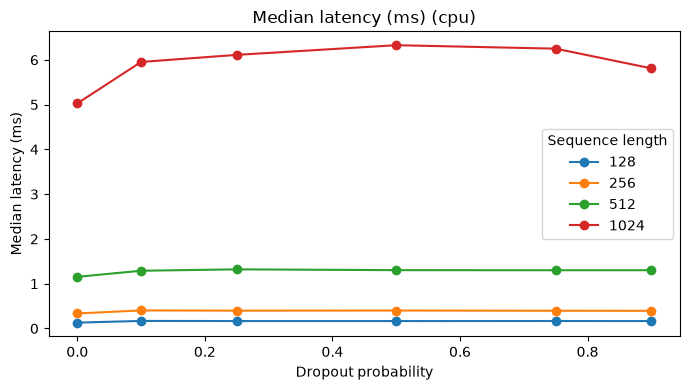

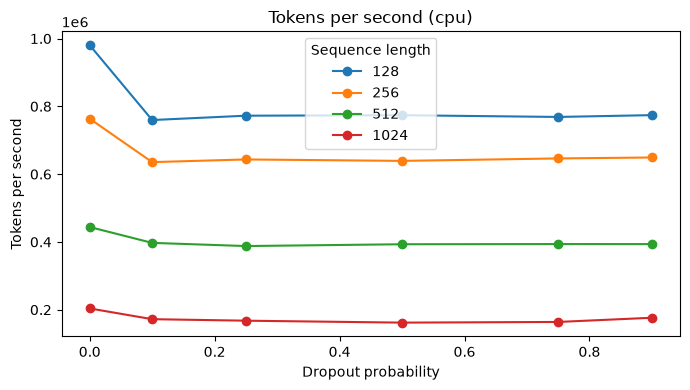

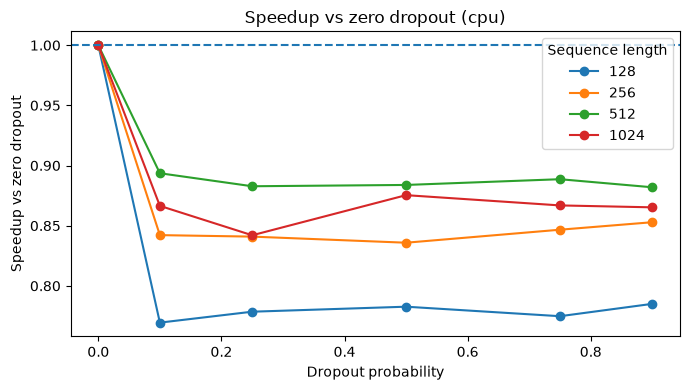

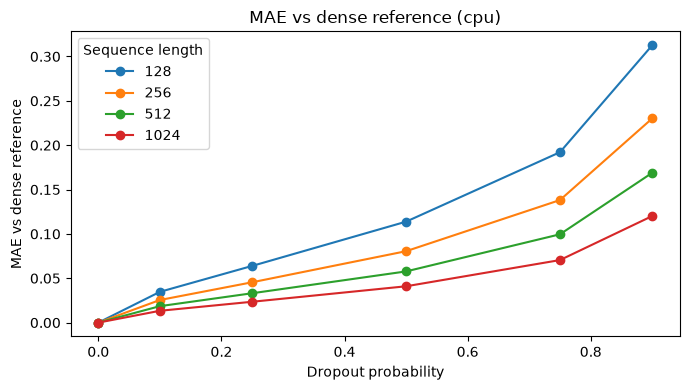

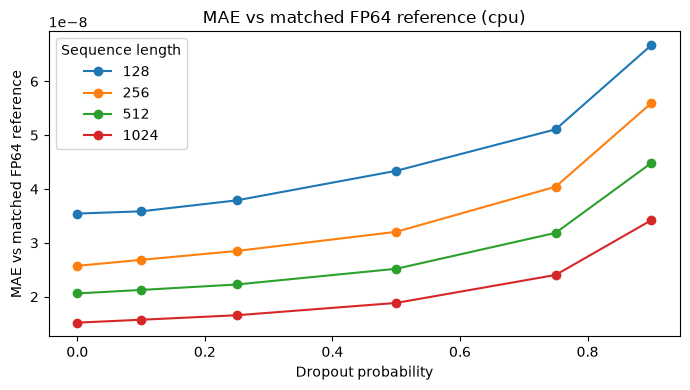

In [9]:
for column, label in [("median_ms", "Median latency (ms)"),
                      ("tokens_per_second", "Tokens per second"),
                      ("speedup", "Speedup vs zero dropout"),
                      ("dense_deviation_mae", "MAE vs dense reference"),
                      ("matched_mae", "MAE vs matched FP64 reference")]:
    plt.figure(figsize=(7, 4))
    for length in lengths:
        part = summary[summary["length"] == length]
        plt.plot(part["dropout"], part[column], marker="o", label=str(length))
    if column == "speedup":
        plt.axhline(1, linestyle="--")
    plt.xlabel("Dropout probability")
    plt.ylabel(label)
    plt.title(label + " (" + device + ")")
    plt.legend(title="Sequence length")
    plt.tight_layout()
    plt.show()

## 10. Interpretation and export
The following descriptive comparisons are calculated directly from the measured results. Timing differences are not evidence of skipped arithmetic: this implementation still computes dense matrix products. CPU measurements cannot establish GPU performance. The five seeds provide a preliminary variability estimate, not a formal significance test.

In [10]:
for length in lengths:
    part = summary[summary["length"] == length]
    first = part[part["dropout"] == 0].iloc[0]
    last = part[part["dropout"] == 0.9].iloc[0]
    print("Length:", length)
    print("Latency at p=0:", round(first["median_ms"], 4), "ms")
    print("Latency at p=0.9:", round(last["median_ms"], 4), "ms")
    print("Paired speedup:", round(last["speedup"], 4))
    print("Dense output deviation:", round(last["dense_deviation_mae"], 6))
    print("Matched FP64 MAE:", format(last["matched_mae"], ".3e"))
    print()

results.to_csv("attention_seed_results.csv", index=False)
raw_times.to_csv("attention_raw_timings.csv", index=False)
summary.to_csv("attention_summary.csv", index=False)
print("CSV files saved.")

Length: 128
Latency at p=0: 0.1306 ms
Latency at p=0.9: 0.1654 ms
Paired speedup: 0.785
Dense output deviation: 0.312705
Matched FP64 MAE: 6.671e-08

Length: 256
Latency at p=0: 0.3353 ms
Latency at p=0.9: 0.3943 ms
Paired speedup: 0.8529
Dense output deviation: 0.230247
Matched FP64 MAE: 5.595e-08

Length: 512
Latency at p=0: 1.1533 ms
Latency at p=0.9: 1.3009 ms
Paired speedup: 0.8819
Dense output deviation: 0.168942
Matched FP64 MAE: 4.483e-08

Length: 1024
Latency at p=0: 5.0263 ms
Latency at p=0.9: 5.809 ms
Paired speedup: 0.8653
Dense output deviation: 0.120189
Matched FP64 MAE: 3.420e-08

CSV files saved.


## 11. Limitations and next stage
RQ1 and RQ4 are addressed only for this dense implementation and the recorded device. RQ3 requires the actual approximate algorithms and a matched reference with an agreed masking convention. The T4 may not support the team's FlashAttention kernels. Before integrating this pilot, confirm the dropout location, causal setting, input dimensions, precision, baseline implementations, GPU model and timing protocol with the team. No claim of algorithmic acceleration or final team-level validation is made here.